# TDI, end to end

Every step visible, **one idea per cell**: a short markdown note saying what to look for,
a cell that does one thing, and a chart with the takeaway printed under it.

**data → labels → splits → features → models → training → validation → submission**

### The one fact that changes the problem

`is_TDI` is not a noisy biological label. It is a deterministic rule over two measured
pIC50 values:

```
is_TDI  =  direct arm was fitted
       AND (pIC50_TDI − pIC50_direct) > log10(2)
       AND  pIC50_TDI > 4.301
```

§3 verifies that live and draws it. §10 uses it as a second modelling route.

### Where the track stands

| | our d′ | best rival | our cut | their cut | the work |
|---|---|---|---|---|---|
| **CYP3A4** | 1.290 | 1.319 | 0.229 | 0.290–0.314 | the **threshold** |
| **CYP2D6** | 0.980 | 1.392 | 0.214 | 0.082 | **discriminability** |

Standing best: MA-MCC **0.3325**, rank 15.

## 1 · Setup and chart style

One cell of constants and one small plotting helper so every later chart is two or three lines. Colours are fixed per isoform throughout — CYP3A4 blue, CYP2D6 orange — so a colour always means the same thing.

In [1]:
import os, sys, time, itertools, warnings
from pathlib import Path

REPO = Path(r'D:\CYP450\cyp')          # <-- edit if the repo lives elsewhere
os.chdir(REPO); sys.path.insert(0, str(REPO))
warnings.filterwarnings('ignore')

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy.stats import norm
from sklearn.metrics import roc_auc_score, roc_curve, matthews_corrcoef

from cypkit import config as CC

DATA, ART = REPO / 'data', REPO / 'artifacts'
CACHE = ART / 'nb_cache'; CACHE.mkdir(parents=True, exist_ok=True)
USE_CACHE = True

ISOS, ALL_ISOS = list(CC.TDI_ISOFORMS), list(CC.ISOFORMS)
SEED, N_FOLDS  = 42, 5

PREVALENCE     = {'CYP3A4': 0.2915, 'CYP2D6': 0.0706}
OUR_DPRIME     = {'CYP3A4': 1.290,  'CYP2D6': 0.980}
BEST_MCC       = {'CYP3A4': 0.4470, 'CYP2D6': 0.2180}
RATE_INFLATION = {'CYP3A4': 0.2290/0.2107, 'CYP2D6': 0.2136/0.1707}
OPTIMAL_RATE   = {'CYP3A4': 0.306,  'CYP2D6': 0.142}     # EFFECTIVE, not submitted
LAST_EFFECTIVE = {'CYP3A4': 0.2290, 'CYP2D6': 0.2136}

# ---- chart style -------------------------------------------------------------------
# Colourblind-checked: worst all-pairs deutan dE 9.2, normal-vision dE 24.0.
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
GREY, INK, MUTED   = '#c9c7bd', '#1a1a19', '#6b6a63'
CLR = {'CYP3A4': BLUE, 'CYP2D6': ORANGE}

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': GREY, 'axes.labelcolor': INK, 'text.color': INK,
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.grid': True, 'grid.color': GREY, 'grid.alpha': 0.35, 'grid.linewidth': 0.6,
    'axes.axisbelow': True, 'legend.frameon': False, 'figure.autolayout': True,
})

def panel(title, xlabel='', ylabel='', figsize=(7, 3.4)):
    '''One axis, house style. Returns (fig, ax).'''
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_title(title, loc='left', fontsize=11, color=INK, pad=10)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    return fig, ax

def panels(title, n=2, figsize=(9.5, 3.4), **kw):
    '''Small multiples -- one panel per endpoint. Never a dual axis.'''
    fig, axes = plt.subplots(1, n, figsize=figsize, **kw)
    fig.suptitle(title, x=0.01, ha='left', fontsize=11, color=INK)
    return fig, np.atleast_1d(axes)

def takeaway(msg):
    '''The one sentence the chart above is for.'''
    print('→ ' + msg)

print('setup done — CYP3A4 =', BLUE, '| CYP2D6 =', ORANGE)

setup done — CYP3A4 = #2a78d6 | CYP2D6 = #eb6834


## 2 · Read the five files

Just shapes. The row counts are the first real clue: the TDI files carry 6,145 compounds
but the inhibition file only 4,905.

In [2]:
def load(n):
    d = pd.read_csv(DATA / n); d.columns = [c.strip() for c in d.columns]; return d

tdi_raw = load('cyp-challenge-TRAIN_TDI.csv')
emax    = load('cyp-challenge-TRAIN_Emax.csv')
inhib   = load('cyp-challenge-TRAIN_inhibition.csv')
screen  = load('cyp-challenge-single-concentration-TRAIN.csv')
test    = load('cyp-challenge-TEST-BLINDED.csv')

for nm, d in [('TRAIN_TDI', tdi_raw), ('TRAIN_Emax', emax), ('TRAIN_inhibition', inhib),
              ('single-conc', screen), ('TEST (blind)', test)]:
    print(f'{nm:18s} {d.shape[0]:6,d} rows x {d.shape[1]:3d} cols')
takeaway('TDI files hold 1,240 more compounds than the inhibition file — '
         'a TDI measurement with no direct-arm curve.')

TRAIN_TDI           6,145 rows x  36 cols
TRAIN_Emax          6,145 rows x  30 cols
TRAIN_inhibition    4,905 rows x  18 cols
single-conc        17,504 rows x  12 cols
TEST (blind)          750 rows x   2 cols
→ TDI files hold 1,240 more compounds than the inhibition file — a TDI measurement with no direct-arm curve.


### 2b · How many `is_TDI` labels exist, and where

Only CYP3A4 and CYP2D6 are scored. But `TRAIN_Emax` carries the label for **all four**
isoforms — the grey bars are 2,698 rows no scored model currently sees.

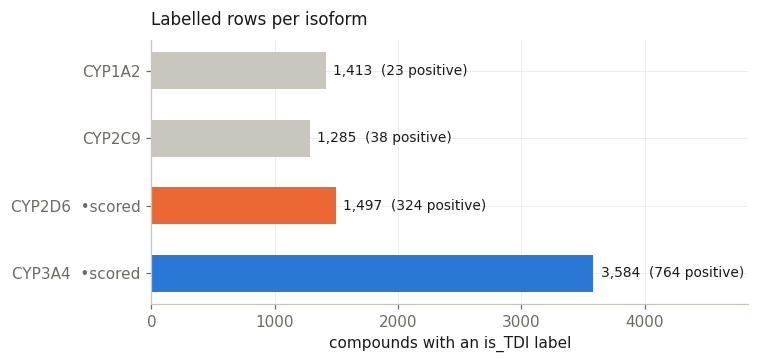

→ 2,698 labelled rows on the two unscored isoforms are currently unused — candidate #1 in §13.


In [3]:
counts = {c: int(emax[f'{c}_is_TDI'].notna().sum()) for c in ALL_ISOS}
pos    = {c: int(emax[f'{c}_is_TDI'].dropna().astype(bool).sum()) for c in ALL_ISOS}

fig, ax = panel('Labelled rows per isoform', xlabel='compounds with an is_TDI label')
y = np.arange(len(ALL_ISOS))
for i, c in enumerate(ALL_ISOS):
    col = CLR.get(c, GREY)
    ax.barh(i, counts[c], color=col, height=0.55)
    ax.barh(i, pos[c],    color=col, height=0.55, alpha=1.0)
    ax.text(counts[c] + 60, i, f'{counts[c]:,}  ({pos[c]:,} positive)',
            va='center', fontsize=9, color=INK)
ax.set_yticks(y, [c + ('  •scored' if c in ISOS else '') for c in ALL_ISOS])
ax.invert_yaxis(); ax.set_xlim(0, max(counts.values()) * 1.35)
plt.show()
takeaway(f'{counts["CYP1A2"]+counts["CYP2C9"]:,} labelled rows on the two unscored '
         f'isoforms are currently unused — candidate #1 in §13.')

## 3 · The label is a rule — verify it

Two candidate readings. The repo's rule requires the direct arm to have been **fitted**;
the challenge blog's narrative counts a compound whose direct arm fell below the floor but
whose TDI arm cleared 4.301 ("inferred positives"). Only one matches the released labels.

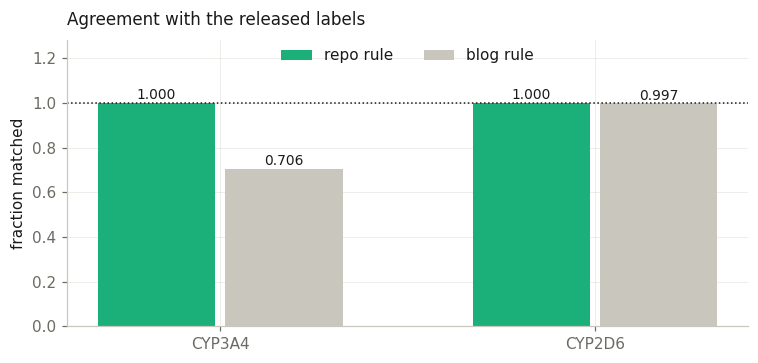

→ The repo rule is exact (1.000 on both). The blog reading fails on CYP3A4 only — it would have looked like a CYP3A4 modelling problem, not a misread label.


In [4]:
LOG2, TDI_FLOOR = float(np.log10(2)), 4.301

def rule(direct, tdi_arm):
    '''Repo rule: direct arm fitted AND shift > log10(2) AND tdi_arm > 4.301.'''
    d, t = np.asarray(direct, float), np.asarray(tdi_arm, float)
    return (~np.isnan(d)) & ((t - np.nan_to_num(d)) > LOG2) & (t > TDI_FLOOR)

def blog_rule(direct, tdi_arm):
    '''Blog narrative: an unfitted direct arm still counts if the TDI arm clears.'''
    d, t = np.asarray(direct, float), np.asarray(tdi_arm, float)
    return (t > TDI_FLOOR) & (np.isnan(d) | ((t - np.nan_to_num(d)) > LOG2))

agree = {}
for c in ISOS:
    has = tdi_raw[f'{c}_is_TDI'].notna()
    y = tdi_raw.loc[has, f'{c}_is_TDI'].astype(bool).to_numpy()
    d = tdi_raw.loc[has, f'{c}_pIC50_direct_inhibition']
    t = tdi_raw.loc[has, f'{c}_pIC50_TDI_condition']
    agree[c] = {'repo rule': (rule(d, t) == y).mean(), 'blog rule': (blog_rule(d, t) == y).mean()}

fig, ax = panel('Agreement with the released labels', ylabel='fraction matched')
x = np.arange(len(ISOS)); w = 0.34
for k, (nm, col) in enumerate([('repo rule', AQUA), ('blog rule', GREY)]):
    v = [agree[c][nm] for c in ISOS]
    ax.bar(x + (k - 0.5) * w, v, w * 0.92, color=col, label=nm)
    for xi, vi in zip(x + (k - 0.5) * w, v):
        ax.text(xi, vi + 0.015, f'{vi:.3f}', ha='center', fontsize=9, color=INK)
ax.axhline(1.0, color=INK, lw=1, ls=':')
ax.set_xticks(x, ISOS); ax.set_ylim(0, 1.28)
ax.legend(loc='upper center', ncol=2, bbox_to_anchor=(.5, 1.02))
plt.show()
takeaway('The repo rule is exact (1.000 on both). The blog reading fails on CYP3A4 only — '
         'it would have looked like a CYP3A4 modelling problem, not a misread label.')

### 3b · The same rule, drawn

Every compound placed by its two measured arms. The rule is just the region above **both**
dashed lines. This is the whole label in one picture — and it shows why the blog reading
misfires: the compounds with no direct-arm fit (plotted at the left edge) are all negative.

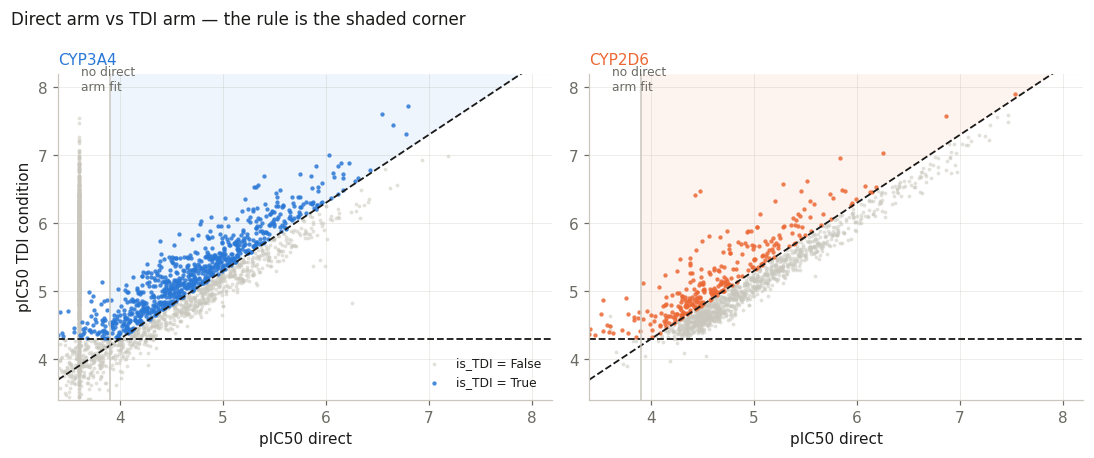

→ 1,249 CYP3A4 compounds sit in the "no direct fit" column against 4 on CYP2D6 — which is exactly why the blog rule fails on one endpoint and not the other.


In [5]:
fig, axes = panels('Direct arm vs TDI arm — the rule is the shaded corner', n=2,
                   figsize=(10, 4.2))
for ax, c in zip(axes, ISOS):
    d = tdi_raw[f'{c}_pIC50_direct_inhibition'].to_numpy(float)
    t = tdi_raw[f'{c}_pIC50_TDI_condition'].to_numpy(float)
    y = tdi_raw[f'{c}_is_TDI']
    m = y.notna().to_numpy() & np.isfinite(t)
    yv = y[m].astype(bool).to_numpy()
    dv, tv = d[m], t[m]
    unfit = np.isnan(dv)
    dv_plot = np.where(unfit, 3.6, dv)            # park unfitted at the left edge
    ax.scatter(dv_plot[~yv], tv[~yv], s=6, c=GREY, alpha=.55, lw=0, label='is_TDI = False')
    ax.scatter(dv_plot[yv],  tv[yv],  s=8, c=CLR[c], alpha=.85, lw=0, label='is_TDI = True')
    lim = (3.4, 8.2)
    xs = np.linspace(*lim, 50)
    ax.plot(xs, xs + LOG2, ls='--', lw=1.2, color=INK)      # shift boundary
    ax.axhline(TDI_FLOOR, ls='--', lw=1.2, color=INK)       # TDI-arm floor
    # shade only where the direct arm WAS fitted -- the rule cannot fire left of 3.9
    xf = np.linspace(3.9, lim[1], 50)
    ax.fill_between(xf, np.maximum(xf + LOG2, TDI_FLOOR), lim[1],
                    color=CLR[c], alpha=.07, lw=0)
    ax.axvline(3.9, color=GREY, lw=1)
    ax.text(3.62, lim[1] - 0.25, 'no direct\narm fit', fontsize=8, color=MUTED)
    ax.set_xlim(*lim); ax.set_ylim(*lim)
    ax.set_title(c, loc='left', fontsize=10, color=CLR[c])
    ax.set_xlabel('pIC50 direct');
axes[0].set_ylabel('pIC50 TDI condition'); axes[0].legend(loc='lower right', fontsize=8)
plt.show()
n3, n2 = [int((tdi_raw[f'{c}_pIC50_direct_inhibition'].isna() &
               tdi_raw[f'{c}_pIC50_TDI_condition'].notna()).sum()) for c in ISOS]
takeaway(f'{n3:,} CYP3A4 compounds sit in the "no direct fit" column against {n2} on '
         f'CYP2D6 — which is exactly why the blog rule fails on one endpoint and not the other.')

## 4 · Build the label table

Long format, one row per (compound, isoform). `shift` and `measurable` come from the
answer, so they are never features — they are §10's regression targets.

In [6]:
def build_labels(frame, isoforms):
    rows = []
    for c in isoforms:
        col = f'{c}_is_TDI'
        if col not in frame.columns: continue
        s = frame[frame[col].notna()]
        rows.append(pd.DataFrame({
            CC.ID_COL: s[CC.ID_COL].to_numpy(), CC.SMILES_COL: s[CC.SMILES_COL].to_numpy(),
            'isoform': c, 'y': s[col].astype(bool).to_numpy(),
            'direct':  s[f'{c}_pIC50_direct_inhibition'].to_numpy(),
            'tdi_arm': s[f'{c}_pIC50_TDI_condition'].to_numpy()}))
    o = pd.concat(rows, ignore_index=True)
    o['measurable'] = o['direct'].notna(); o['shift'] = o['tdi_arm'] - o['direct']
    return o

lab = build_labels(tdi_raw, ISOS)
print(lab.groupby('isoform').agg(n=('y','size'), positives=('y','sum'),
      rate=('y','mean'), measurable=('measurable','mean')).to_string(
      float_format=lambda x: f'{x:.3f}'))
takeaway('Both endpoints look balanced at ~21% positive here. The next chart shows why '
         'that is misleading.')

            n  positives  rate  measurable
isoform                                   
CYP2D6   1497        324 0.216       0.997
CYP3A4   3584        764 0.213       0.652
→ Both endpoints look balanced at ~21% positive here. The next chart shows why that is misleading.


### 4b · Class balance — the number that governs how you read every local score

The training set and the blind set are **not the same population**. The blind prevalence
was recovered by inverting every competitor's published accuracy/precision/recall, and it
came out identical to four decimals across all of them.

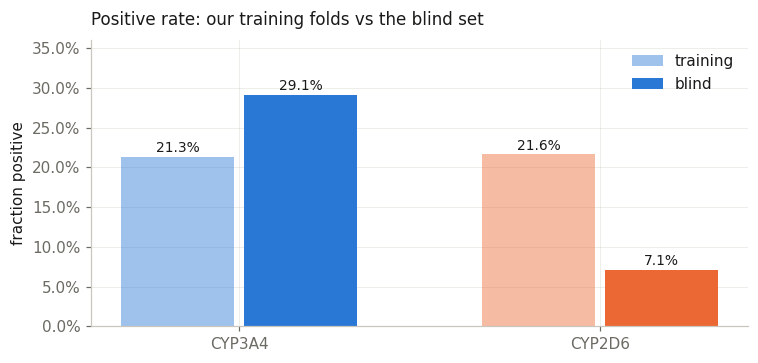

→ CYP3A4 trains under-represented (21%→29%); CYP2D6 trains THREE TIMES too rich (22%→7%). Every CYP2D6 score below is measured on the wrong population.


In [7]:
fig, ax = panel('Positive rate: our training folds vs the blind set',
                ylabel='fraction positive')
x = np.arange(len(ISOS)); w = 0.34
tr = [lab.loc[lab.isoform == c, 'y'].mean() for c in ISOS]
bl = [PREVALENCE[c] for c in ISOS]
ax.bar(x - w/2, tr, w*0.92, color=[CLR[c] for c in ISOS], alpha=.45, label='training')
ax.bar(x + w/2, bl, w*0.92, color=[CLR[c] for c in ISOS], label='blind')
for xi, v in zip(x - w/2, tr): ax.text(xi, v+.006, f'{v:.1%}', ha='center', fontsize=9)
for xi, v in zip(x + w/2, bl): ax.text(xi, v+.006, f'{v:.1%}', ha='center', fontsize=9)
ax.set_xticks(x, ISOS); ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylim(0, .36); ax.legend(loc='upper right')
plt.show()
takeaway('CYP3A4 trains under-represented (21%→29%); CYP2D6 trains THREE TIMES too rich '
         '(22%→7%). Every CYP2D6 score below is measured on the wrong population.')

### 4c · Where the label boundary actually falls

The rule cuts at `shift > 0.301`. Plotting the shift shows how much of the population sits
right on that line — which is what makes the boolean lossy and §10 worth trying.

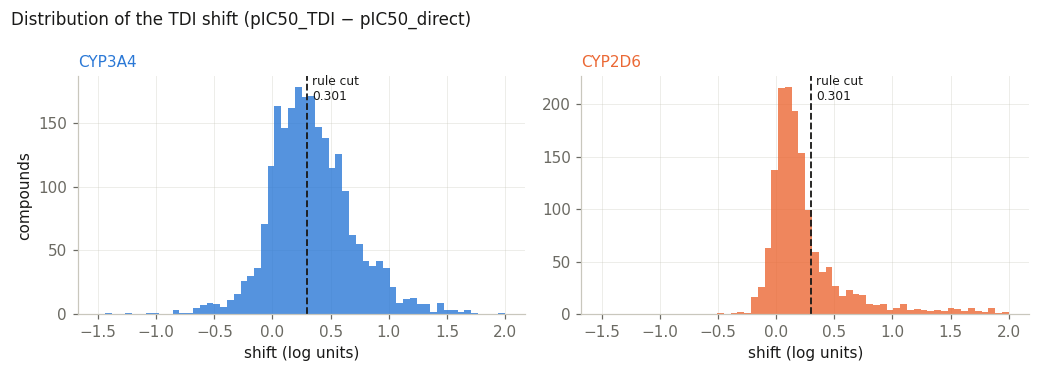

→ The mass piles up right at the cut, so the boolean throws away most of the signal the shift carries — that is the argument for Route B in §10.


In [8]:
fig, axes = panels('Distribution of the TDI shift (pIC50_TDI − pIC50_direct)', n=2)
for ax, c in zip(axes, ISOS):
    s = lab.loc[(lab.isoform == c) & lab['shift'].notna(), 'shift']
    ax.hist(s, bins=60, range=(-1.5, 2.0), color=CLR[c], alpha=.8, lw=0)
    ax.axvline(LOG2, color=INK, ls='--', lw=1.2)
    ax.text(LOG2 + .04, ax.get_ylim()[1]*.9, 'rule cut\n0.301', fontsize=8, color=INK)
    ax.set_title(c, loc='left', fontsize=10, color=CLR[c]); ax.set_xlabel('shift (log units)')
axes[0].set_ylabel('compounds')
plt.show()
takeaway('The mass piles up right at the cut, so the boolean throws away most of the '
         'signal the shift carries — that is the argument for Route B in §10.')

## 5 · Splitting — three options, one diagnostic

The diagnostic is **max Tanimoto from each held-out compound to the training half**. The
blind set sits at 0.587 from our training set, so that is the number to hit. Missing it
in either direction matters: above it and the split flatters us, below it and our local
scores understate the model.

In [9]:
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import AllChem
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.model_selection import GroupKFold
RDLogger.DisableLog('rdApp.*')
_GEN = AllChem.GetMorganGenerator(radius=2, fpSize=2048)

compounds = lab[[CC.ID_COL, CC.SMILES_COL]].drop_duplicates(CC.ID_COL).reset_index(drop=True)
mols = [Chem.MolFromSmiles(s) for s in compounds[CC.SMILES_COL]]
fps  = [_GEN.GetFingerprint(m) if m is not None else None for m in mols]

def heldout_sim(fold_of):
    out = np.zeros(len(fps))
    for k in sorted(set(fold_of)):
        q = [i for i in range(len(fps)) if fold_of[i] == k and fps[i] is not None]
        r = [fps[i] for i in range(len(fps)) if fold_of[i] != k and fps[i] is not None]
        for i in q: out[i] = max(DataStructs.BulkTanimotoSimilarity(fps[i], r))
    return out

splits = {}
splits['random'] = np.random.default_rng(SEED).permutation(len(compounds)) % N_FOLDS
scaf = np.array([MurckoScaffold.MurckoScaffoldSmiles(mol=m, includeChirality=True)
                 if m is not None else '' for m in mols])
f = np.zeros(len(compounds), int)
for k, (_, te) in enumerate(GroupKFold(n_splits=N_FOLDS).split(compounds, groups=scaf)): f[te] = k
splits['scaffold'] = f
frozen = pd.read_csv(ART / 'folds.csv')
m = compounds[CC.ID_COL].map(dict(zip(frozen[CC.ID_COL], frozen['fold'])))
if m.isna().any():
    from cypkit import splits as SP
    m.loc[m.isna()] = SP.assign_extra_to_folds(
        compounds.loc[m.isna(), CC.SMILES_COL].tolist(), frozen)
splits['butina (frozen)'] = m.to_numpy(int)

sims = {k: heldout_sim(v) for k, v in splits.items()}
print({k: round(float(np.median(v)), 3) for k, v in sims.items()})

{'random': 0.449, 'scaffold': 0.44, 'butina (frozen)': 0.441}


### 5b · The three splits, drawn against the target

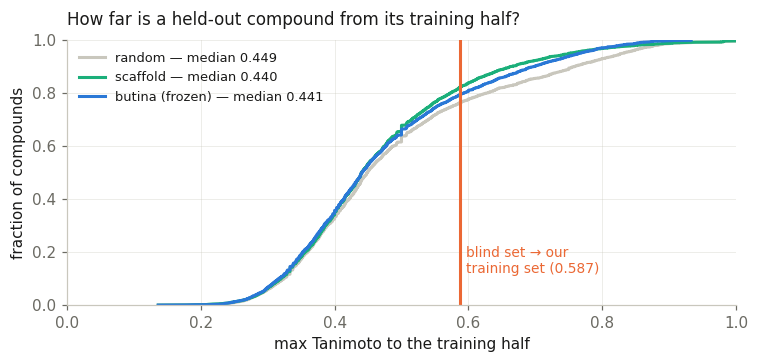

→ All three sit near 0.44 — well BELOW the blind set. Cross-validation here is HARDER than the real task, so local scores understate rather than flatter.


In [10]:
fig, ax = panel('How far is a held-out compound from its training half?',
                xlabel='max Tanimoto to the training half', ylabel='fraction of compounds')
for (nm, v), col in zip(sims.items(), [GREY, AQUA, BLUE]):
    xs = np.sort(v); ys = np.arange(1, len(xs)+1) / len(xs)
    ax.plot(xs, ys, lw=2, color=col, label=f'{nm} — median {np.median(v):.3f}')
ax.legend(loc='upper left', fontsize=8.5)
ax.axvline(0.587, color=ORANGE, lw=2)
ax.text(0.597, .12, 'blind set → our\ntraining set (0.587)', fontsize=9, color=ORANGE)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.show()
FOLD = splits['butina (frozen)']
lab['fold'] = lab[CC.ID_COL].map(dict(zip(compounds[CC.ID_COL], FOLD)))
takeaway('All three sit near 0.44 — well BELOW the blind set. Cross-validation here is '
         'HARDER than the real task, so local scores understate rather than flatter.')

## 6 · Molecular features — seven blocks

`tdialert` is the one that encodes the mechanism: reactive-metabolite SMARTS (furans,
thiophenes, terminal alkynes, anilines, methylenedioxyphenyl). TDI is mechanism-based, so
it is the only block that speaks the right language directly.

`avalon` (1024 bits) is the newest addition, and it is here for a specific reason. Avalon
enumerates substructures by a **different algorithm** from Morgan, so it tends to disagree
with `ecfp` rather than duplicate it — and §9c keeps showing that disagreement, not raw
quality, is what this blend is short of. Note it takes a bit count, not a radius:
`nBits=1024` is the whole specification, there is no radius to set.

train:
  cached: rdkit, cyp, tdialert, ecfp, fcfp, avalon
blind:
  cached: rdkit, cyp, tdialert, ecfp, fcfp, avalon


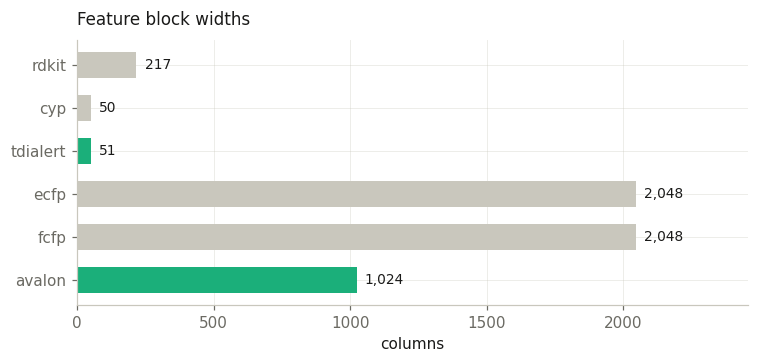

→ 5,438 columns total. The 51 mechanism alerts are 1% of the width — §9 shows whether they punch above it.


In [11]:
from cypkit import features as F, cyp_descriptors as CD, tdi_alerts as TA

BLOCKS = ['rdkit', 'cyp', 'tdialert', 'ecfp',  'fcfp', 'avalon']  # <-- edit 

def build_block(name, smi):
    if   name == 'rdkit':    X, _ = F.rdkit_2d(smi);    cols = F.descriptor_names()
    elif name == 'cyp':      X, _ = CD.calculate(smi);  cols = CD.feature_names()
    elif name == 'tdialert': X, _ = TA.calculate(smi);  cols = TA.feature_names()
    else:                    X, _, cols = F.fingerprint_block(smi, name)
    return np.nan_to_num(np.asarray(X, np.float32), nan=0., posinf=0., neginf=0.), list(cols)

def bank(smi, tag):
    '''Build the feature matrix, caching ONE FILE PER BLOCK.

    Caching the whole matrix in a single file was a bug: the filename recorded nothing
    about which blocks were inside, so adding `avalon` to BLOCKS silently reloaded the
    six-block file and SPANS came back without it -- a KeyError three cells later, long
    after the cause. Per-block files make the cache key match the thing being cached, and
    they make editing BLOCKS cheap: add one and only that one is computed, remove one and
    nothing is recomputed at all.
    '''
    mats, spans, at, built, reused = [], {}, 0, [], []
    for b in BLOCKS:
        f = CACHE / f'X_{tag}_{b}.npy'
        if USE_CACHE and f.exists():
            Xb = np.load(f); reused.append(b)
        else:
            t0 = time.time(); Xb, _ = build_block(b, smi)
            np.save(f, Xb); built.append(f'{b} ({time.time()-t0:.0f}s)')
        if Xb.shape[0] != len(smi):
            raise ValueError(f'cached {f.name} has {Xb.shape[0]} rows, expected '
                             f'{len(smi)} -- delete {CACHE} and rerun')
        spans[b] = (at, at + Xb.shape[1]); at += Xb.shape[1]; mats.append(Xb)
    if reused: print(f'  cached: {", ".join(reused)}')
    if built:  print(f'  built : {", ".join(built)}')
    return np.hstack(mats), spans

print('train:'); Xtr, SPANS = bank(compounds[CC.SMILES_COL].tolist(), 'train')
print('blind:'); Xte, SPANS_TE = bank(test[CC.SMILES_COL].tolist(), 'test')
assert SPANS == SPANS_TE, 'train and blind banks disagree on block layout'
row_of = {i: k for k, i in enumerate(compounds[CC.ID_COL])}

def view(X, blocks):
    '''Columns for a subset of blocks. Names a missing block instead of KeyError.'''
    missing = [b for b in blocks if b not in SPANS]
    if missing:
        raise KeyError(f'{missing} not in the feature bank. SPANS has {list(SPANS)}. '
                       f'Add them to BLOCKS above and re-run this cell.')
    return np.hstack([X[:, SPANS[b][0]:SPANS[b][1]] for b in blocks])

fig, ax = panel('Feature block widths', xlabel='columns')
w = [SPANS[b][1]-SPANS[b][0] for b in BLOCKS]
ax.barh(range(len(BLOCKS)), w, color=[AQUA if b in ('tdialert', 'avalon') else GREY for b in BLOCKS],
        height=.6)
for i, v in enumerate(w): ax.text(v+30, i, f'{v:,}', va='center', fontsize=9)
ax.set_yticks(range(len(BLOCKS)), BLOCKS); ax.invert_yaxis()
ax.set_xlim(0, max(w)*1.2)
plt.show()
takeaway(f'{Xtr.shape[1]:,} columns total. The 51 mechanism alerts are 1% of the width — '
         f'§9 shows whether they punch above it.')

### 6b · Is the blind set inside our chemical space?

A PCA of the physicochemical block. If the orange cloud sat outside the grey one, no model
trained here could speak about it.

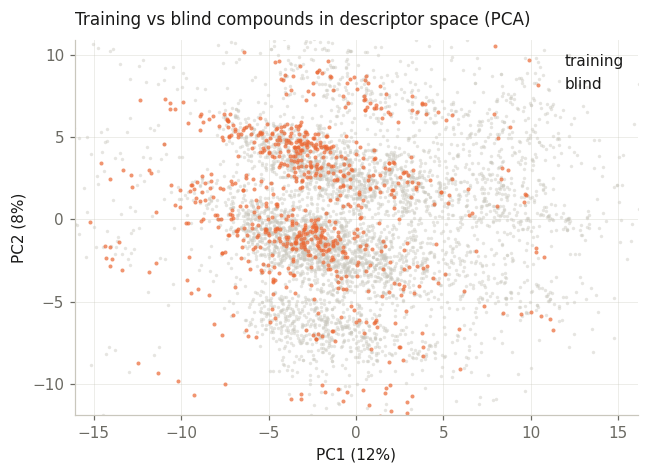

→ The blind set sits inside our training cloud — this is a knowledge problem, not a coverage problem, which matches the applicability-domain analysis.


In [12]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
B = ['rdkit', 'cyp']
s = StandardScaler().fit(view(Xtr, B))
p = PCA(n_components=2, random_state=SEED).fit(s.transform(view(Xtr, B)))
A, Bp = p.transform(s.transform(view(Xtr, B))), p.transform(s.transform(view(Xte, B)))

fig, ax = panel('Training vs blind compounds in descriptor space (PCA)',
                xlabel=f'PC1 ({p.explained_variance_ratio_[0]:.0%})',
                ylabel=f'PC2 ({p.explained_variance_ratio_[1]:.0%})', figsize=(6, 4.4))
ax.scatter(A[:, 0], A[:, 1], s=5, c=GREY, alpha=.45, lw=0, label='training')
ax.scatter(Bp[:, 0], Bp[:, 1], s=7, c=ORANGE, alpha=.7, lw=0, label='blind')
ax.legend(loc='upper right'); ax.set_xlim(np.percentile(A[:,0],[.5,99.5]))
ax.set_ylim(np.percentile(A[:,1],[.5,99.5]))
plt.show()
takeaway('The blind set sits inside our training cloud — this is a knowledge problem, '
         'not a coverage problem, which matches the applicability-domain analysis.')

## 7 · The model zoo

Each entry is a function plus the feature blocks it sees. Add one by adding a dict entry.
Feature subset matters as much as algorithm: kNN and the Tanimoto SVMs get a fingerprint
**only**, because a Tanimoto neighbourhood over mixed continuous descriptors is meaningless.

Two notes on the SVMs. They return `decision_function`, not `predict_proba` — Platt
scaling costs an internal 5-fold CV to produce a *monotone* transform, and rank-blending
needs only the ordering, so the probabilities would be pure expense. And `svm_tan` /
`svm_aval` use a **precomputed Tanimoto kernel**, which is both the correct similarity for
binary bits and far cheaper than an RBF over thousands of sparse columns.

`class_weight='balanced'` is on for both SVMs. That is the §4b prevalence gap being
addressed for the first time in this pool, so watch §9 for whether it helps **CYP2D6**
specifically — that is the endpoint trained three times too rich in positives.

In [13]:
import lightgbm as lgb
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

N_ROUNDS = 300

def _tanimoto_kernel(A, B):
    '''Tanimoto similarity between two binary matrices, as ONE matmul.

    sklearn's pairwise_distances(metric='jaccard') runs a Python-level loop over pairs
    and takes minutes on 3.5k x 2048; this is seconds. inter = A.B', and the union is
    |A| + |B| - inter, so the whole kernel is arithmetic on that product.
    '''
    A = np.asarray(A, np.float32); B = np.asarray(B, np.float32)
    inter = A @ B.T
    na = A.sum(1)[:, None]; nb = B.sum(1)[None, :]
    return inter / np.maximum(na + nb - inter, 1e-9)


def _lgb(Xa, y, Xb, **kw):
    p = dict(objective='binary', n_estimators=N_ROUNDS, learning_rate=.05, num_leaves=31,
             subsample=.8, colsample_bytree=.6, verbosity=-1, random_state=SEED); p.update(kw)
    return lgb.LGBMClassifier(**p).fit(Xa, y).predict_proba(Xb)[:, 1]

def _forest(cls):
    def f(Xa, y, Xb):
        return cls(n_estimators=400, min_samples_leaf=2, n_jobs=-1,
                   random_state=SEED).fit(Xa, y).predict_proba(Xb)[:, 1]
    return f

def _logreg(Xa, y, Xb):
    s = StandardScaler().fit(Xa)
    return LogisticRegression(max_iter=2000, C=.1).fit(
        s.transform(Xa), y).predict_proba(s.transform(Xb))[:, 1]

def _knn(k):
    def f(Xa, y, Xb):
        # Tanimoto kNN by hand, for the same speed reason as the SVM below: sklearn's
        # 'jaccard' metric is a per-pair Python loop. Vote = mean label of the k nearest.
        K = _tanimoto_kernel(Xb, Xa)
        idx = np.argpartition(-K, kth=min(k, K.shape[1] - 1), axis=1)[:, :k]
        return np.asarray(y)[idx].mean(1)
    return f

def _xgb(Xa, y, Xb):
    # scale_pos_weight is the hook for the 22%-vs-7% prevalence gap in section 4b:
    # set it to neg/pos to train as if balanced, leave at 1 to match LightGBM.
    return xgb.XGBClassifier(
        n_estimators=N_ROUNDS, learning_rate=.05, max_depth=6, subsample=.8,
        colsample_bytree=.6, reg_lambda=1.0, eval_metric='logloss', n_jobs=-1,
        tree_method='hist', random_state=SEED).fit(Xa, y).predict_proba(Xb)[:, 1]

def _svm_rbf(Xa, y, Xb):
    # decision_function, NOT predict_proba: Platt scaling costs an internal 5-fold CV to
    # produce a MONOTONE transform, and rank-blending needs only the ordering.
    sc = StandardScaler().fit(Xa)
    return SVC(C=1.0, gamma='scale', kernel='rbf', class_weight='balanced').fit(
        sc.transform(Xa), y).decision_function(sc.transform(Xb))

def _svm_tanimoto(Xa, y, Xb):
    # PRECOMPUTED Tanimoto kernel -- the right similarity for binary bits, and far
    # cheaper than an RBF over thousands of sparse columns.
    Ka, Kb = _tanimoto_kernel(Xa, Xa), _tanimoto_kernel(Xb, Xa)
    return SVC(C=1.0, kernel='precomputed', class_weight='balanced').fit(
        Ka, y).decision_function(Kb)

ZOO = {
 'lgb_full' : dict(fn=_lgb, blocks=['rdkit','cyp','tdialert','ecfp','maccs']),
 'lgb_desc' : dict(fn=_lgb, blocks=['rdkit','cyp','tdialert']),
 'lgb_alert': dict(fn=_lgb, blocks=['cyp','tdialert']),
 'rf'       : dict(fn=_forest(RandomForestClassifier), blocks=['rdkit','cyp','tdialert','maccs']),
 'et'       : dict(fn=_forest(ExtraTreesClassifier),   blocks=['rdkit','cyp','tdialert','maccs']),
 'logreg'   : dict(fn=_logreg, blocks=['rdkit','cyp','tdialert']),
 'knn_ecfp' : dict(fn=_knn(15), blocks=['ecfp']),
 'knn_fcfp' : dict(fn=_knn(15), blocks=['fcfp']),
 'knn_aval' : dict(fn=_knn(15), blocks=['avalon']),
 'xgb'      : dict(fn=_xgb, blocks=['rdkit','cyp','tdialert','ecfp','maccs']),
 'xgb_aval' : dict(fn=_xgb, blocks=['rdkit','cyp','tdialert','avalon']),
 'svm_rbf'  : dict(fn=_svm_rbf, blocks=['rdkit','cyp','tdialert']),
 'svm_tan'  : dict(fn=_svm_tanimoto, blocks=['ecfp']),
 'svm_aval' : dict(fn=_svm_tanimoto, blocks=['avalon']),
}
# Fail here, not deep inside the CV loop, if a member names a block BLOCKS does not have.
_bad = {n: [b for b in v['blocks'] if b not in SPANS] for n, v in ZOO.items()}
_bad = {n: m for n, m in _bad.items() if m}
if _bad:
    raise KeyError(f'these members want blocks that are not built: {_bad}. '
                   f'Add them to BLOCKS in section 6, or drop the members.')
for n, sp in ZOO.items():
    print(f'  {n:10s} {sum(SPANS[b][1]-SPANS[b][0] for b in sp["blocks"]):6,d} cols  '
          f'{sp["blocks"]}')

KeyError: "these members want blocks that are not built: {'lgb_full': ['maccs'], 'rf': ['maccs'], 'et': ['maccs'], 'xgb': ['maccs']}. Add them to BLOCKS in section 6, or drop the members."

## 8 · Training — with a progress line, not a wall of text

Per endpoint, per model, per fold: fit on the other folds, predict the held-out one.
One line per model as it finishes, with the fold-by-fold AUC so instability is visible
while it runs rather than after.

In [ ]:
def cross_validate(fn, blocks, sub):
    X = view(Xtr, blocks)
    rows = np.array([row_of[i] for i in sub[CC.ID_COL]])
    y, f = sub['y'].to_numpy().astype(int), sub['fold'].to_numpy()
    out, per_fold = np.full(len(sub), np.nan), []
    for k in sorted(set(f)):
        tr, te = f != k, f == k
        out[te] = fn(X[rows[tr]], y[tr], X[rows[te]])
        per_fold.append(roc_auc_score(y[te], out[te]))
    return out, per_fold

oof, folds_auc = {c: {} for c in ISOS}, {c: {} for c in ISOS}
for c in ISOS:
    sub = lab[lab.isoform == c].reset_index(drop=True)
    print(f'\n{c}  ({len(sub):,} rows, {sub.y.mean():.1%} positive)')
    for i, (name, spec) in enumerate(ZOO.items(), 1):
        t0 = time.time()
        s, pf = cross_validate(spec['fn'], spec['blocks'], sub)
        oof[c][name], folds_auc[c][name] = s, pf
        print(f'  [{i}/{len(ZOO)}] {name:10s} AUC {roc_auc_score(sub.y, s):.4f}   '
              f'folds ' + ' '.join(f'{v:.3f}' for v in pf) +
              f'   {time.time()-t0:5.1f}s', flush=True)
    oof[c]['_y'] = sub.y.to_numpy().astype(int)
    oof[c]['_fold'] = sub['fold'].to_numpy()      # needed by §9e's nested selection
names = list(ZOO)

### 8b · Fold-to-fold stability

A model whose folds scatter widely is not really better than one below it — the spread is
the error bar on every number in §9.

In [ ]:
fig, axes = panels('Per-fold AUC (dot = fold, bar = mean)', n=2, figsize=(10, 4.2))
order = sorted(names, key=lambda n: np.mean([np.mean(folds_auc[c][n]) for c in ISOS]))
for ax, c in zip(axes, ISOS):
    for i, n in enumerate(order):
        v = folds_auc[c][n]
        ax.plot(v, [i]*len(v), 'o', ms=5, color=CLR[c], alpha=.45, mew=0)
        ax.plot([np.mean(v)], [i], '|', ms=18, color=INK, mew=2)
    ax.set_yticks(range(len(order)), order, fontsize=9)
    ax.axvline(.5, color=GREY, lw=1, ls=':')
    ax.set_title(c, loc='left', fontsize=10, color=CLR[c]); ax.set_xlabel('AUC')
plt.show()
sp = {c: np.mean([np.ptp(folds_auc[c][n]) for n in names]) for c in ISOS}
takeaway(f'Mean fold spread: CYP3A4 {sp["CYP3A4"]:.3f}, CYP2D6 {sp["CYP2D6"]:.3f}. '
         f'Differences smaller than that are not differences.')

## 9 · Which models work?

Read **AUC**, not MCC — a best-threshold MCC is chosen on the data it scores, so it is a
ceiling with a different amount of optimism per model.

In [ ]:
def rank01(x):
    r = pd.Series(x).rank().to_numpy(); return (r - r.min()) / (r.max() - r.min())
def blend_of(c, ms): return np.mean([rank01(oof[c][m]) for m in ms], axis=0)

auc = {c: {n: roc_auc_score(oof[c]['_y'], oof[c][n]) for n in names} for c in ISOS}
for c in ISOS: auc[c]['BLEND'] = roc_auc_score(oof[c]['_y'], blend_of(c, names))

fig, axes = panels('Out-of-fold AUC by model', n=2, figsize=(10, 4.2))
for ax, c in zip(axes, ISOS):
    order = sorted(auc[c], key=auc[c].get)
    cols = [INK if n == 'BLEND' else CLR[c] for n in order]
    ax.barh(range(len(order)), [auc[c][n] for n in order], color=cols, height=.6)
    for i, n in enumerate(order):
        ax.text(auc[c][n]+.004, i, f'{auc[c][n]:.3f}', va='center', fontsize=8.5)
    ax.set_yticks(range(len(order)), order, fontsize=9)
    ax.axvline(.5, color=GREY, lw=1, ls=':')
    ax.set_xlim(.45, max(auc[c].values())*1.09)
    ax.set_title(c, loc='left', fontsize=10, color=CLR[c]); ax.set_xlabel('AUC')
plt.show()
takeaway(f'Blend {auc["CYP3A4"]["BLEND"]:.3f} / {auc["CYP2D6"]["BLEND"]:.3f}. '
         f'Blind AUC implied by our scored submission: 0.820 / 0.756 — CYP2D6 is where '
         f'local and blind disagree most.')

### 9b · The blend's ROC, both endpoints

In [ ]:
fig, ax = panel('ROC of the rank blend, out of fold',
                xlabel='false positive rate', ylabel='true positive rate', figsize=(5.4, 4.4))
ax.plot([0,1],[0,1], ls=':', color=GREY, lw=1)
for c in ISOS:
    fpr, tpr, _ = roc_curve(oof[c]['_y'], blend_of(c, names))
    ax.plot(fpr, tpr, lw=2, color=CLR[c])
    i = int(len(fpr)*.55)
    ax.text(fpr[i]+.03, tpr[i]-.05, f'{c}  {auc[c]["BLEND"]:.3f}', color=CLR[c], fontsize=9)
ax.set_xlim(0,1); ax.set_ylim(0,1)
plt.show()
takeaway('CYP3A4 is a working model; CYP2D6 is close to the diagonal out of fold — '
         'though §11 shows that is partly the population mismatch, not the model.')

### 9c · Are the members saying different things?

A blend gains from **disagreement**. Anything above ~0.95 is one member counted twice.

In [ ]:
fig, axes = panels('Rank-correlation between members', n=2, figsize=(11, 4.6))
for ax, c in zip(axes, ISOS):
    M = pd.DataFrame({n: oof[c][n] for n in names}).rank().corr().to_numpy()
    ax.imshow(M, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(len(names)), names, rotation=90, fontsize=8)
    ax.set_yticks(range(len(names)), names, fontsize=8)
    # print the value in every cell -- an 8x8 grid reads better as numbers than as a ramp,
    # and it avoids a colorbar (which autolayout parks on top of the second panel)
    for i in range(len(names)):
        for j in range(len(names)):
            if i == j: continue
            hot = M[i, j] > .95
            ax.text(j, i, f'{M[i,j]:.2f}'.lstrip('0'), ha='center', va='center',
                    fontsize=7, fontweight='bold' if hot else 'normal',
                    color=ORANGE if hot else ('white' if M[i, j] > .6 else INK))
    ax.grid(False); ax.set_title(c, loc='left', fontsize=10, color=CLR[c])
plt.show()
takeaway('Darker = more redundant. An "!" marks a pair above 0.95 that is silently '
         'double-weighted in the rank average.')

### 9d · Is every member paying for its place?

In [ ]:
fig, ax = panel('Change in blend AUC when a member is REMOVED', xlabel='Δ AUC')
rows = {c: [roc_auc_score(oof[c]['_y'], blend_of(c, [x for x in names if x != m]))
            - auc[c]['BLEND'] for m in names] for c in ISOS}
y = np.arange(len(names)); h = .36
for k, c in enumerate(ISOS):
    ax.barh(y + (k-.5)*h, rows[c], h*.9, color=CLR[c], label=c)
ax.axvline(0, color=INK, lw=1)
ax.axvspan(-.005, .005, color=GREY, alpha=.3, lw=0)
ax.set_yticks(y, names, fontsize=9); ax.invert_yaxis()
ax.legend(loc='lower right')
ax.set_xlabel('Δ AUC     (grey band = noise, |Δ| < 0.005)')
plt.show()
takeaway('Bars to the RIGHT of zero are members that were HURTING the blend. Only trust '
         'one outside the grey band, and only when the heatmap agrees it is redundant.')

### 9e · Stop averaging everything — choose the members

§9 shows the thing that should stop you: on **CYP2D6 the equal-weight blend is beaten by
two of its own members**. A blend that loses to something it contains is not aggregating,
it is diluting — the tree learners sitting near 0.57 each drag the mean down by their
share.

The obvious fix, *keep the best-scoring members*, is the classic way to fool yourself,
because "best" was measured on the very pool you would then score. So the subset is chosen
on four folds and scored on the fifth, rotated. Nothing is ever graded on data that shaped
it. The absolute numbers come out low — each held-out fifth is small — so read this chart
as **a ranking of strategies**, never as a forecast.

In [ ]:
def _sel_equal(rk, y, tr, ns): return list(ns)

def _sel_topk(k):
    def f(rk, y, tr, ns):
        s = {m: roc_auc_score(y[tr], rk[m][tr]) for m in ns}
        return sorted(ns, key=lambda m: -s[m])[:k]
    return f

def _sel_greedy(rk, y, tr, ns):
    '''Add whichever member most improves the TRAIN-fold blend; stop when none does.
    Selects for CONTRIBUTION, not for individual quality -- a mediocre member wrong in a
    different place earns its seat, a third near-copy does not.'''
    chosen, best, pool = [], -np.inf, list(ns)
    while pool:
        a, m = max((roc_auc_score(y[tr], blend_r(rk, chosen + [m])[tr]), m) for m in pool)
        if a <= best: break
        chosen.append(m); pool.remove(m); best = a
    return chosen

def blend_r(rk, ms): return np.mean([rk[m] for m in ms], axis=0)

STRATS = {'equal': _sel_equal, 'top-3': _sel_topk(3), 'top-5': _sel_topk(5),
          'greedy': _sel_greedy}
nested, votes, picked = {}, {}, {}
for c in ISOS:
    y = np.asarray(oof[c]['_y']).astype(int)
    rk = {m: rank01(oof[c][m]) for m in names}
    fld = np.asarray(oof[c]['_fold'])
    nested[c] = {}; votes[c] = {}
    for nm, fn in STRATS.items():
        sc, vt = [], []
        for k in sorted(set(fld)):
            te = fld == k; ms = fn(rk, y, ~te, names)
            sc.append(roc_auc_score(y[te], blend_r(rk, ms)[te])); vt += ms
        nested[c][nm] = np.mean(sc); votes[c][nm] = pd.Series(vt).value_counts()
    win = max(nested[c], key=nested[c].get)
    picked[c] = STRATS[win](rk, y, np.ones(len(y), bool), names)

fig, axes = panels('Held-out AUC by blending STRATEGY (subset chosen on other folds)',
                   n=2, figsize=(10, 3.6))
for ax, c in zip(axes, ISOS):
    ks = list(STRATS); v = [nested[c][k] for k in ks]
    ax.bar(ks, v, color=[INK if k != 'equal' else GREY for k in ks], width=.6)
    for i, t in enumerate(v): ax.text(i, t+.002, f'{t:.3f}', ha='center', fontsize=8.5)
    ax.set_ylim(min(v)-.02, max(v)+.015)
    ax.set_title(c, loc='left', fontsize=10, color=CLR[c]); ax.set_ylabel('AUC')
plt.show()
for c in ISOS:
    g = nested[c][max(nested[c], key=nested[c].get)] - nested[c]['equal']
    print(f'{c}: best strategy beats equal by {g:+.4f}  ->  keeps {len(picked[c])} '
          f'of {len(names)} members')
    print(f'   {picked[c]}')
takeaway('Grey = what we have always submitted. If a dark bar clears it by more than the '
         'fold-to-fold spread, the equal blend is what has been costing you — and the fix '
         'is free, since every member is already trained.')

Before trusting a pick, ask how often it survived. A greedy path is a chain of argmaxes
over noisy AUC differences, so it can take a different route on a slightly different
sample. A member chosen in 5 folds of 5 is a finding; one chosen in 1 is a coin flip —
and two members that are near-copies will split each other's votes while being
interchangeable in the blend, which the AUC column will show as a tie.

In [ ]:
fig, axes = panels('How many nested folds each member survived selection in', n=2,
                   figsize=(10, 4.2))
for ax, c in zip(axes, ISOS):
    win = max(nested[c], key=nested[c].get)
    v = votes[c][win].sort_values()
    ax.barh(range(len(v)), v.values, color=CLR[c], height=.6)
    ax.set_yticks(range(len(v)), v.index, fontsize=9)
    ax.set_xlim(0, N_FOLDS); ax.set_xlabel(f'folds (of {N_FOLDS})')
    ax.set_title(f'{c} — {win}', loc='left', fontsize=10, color=CLR[c])
plt.show()
takeaway('Trust a member at the right edge. One or two votes means the full-pool pick '
         'landed on it by luck — check whether an alternative gives the same AUC before '
         'letting it into the submission.')

## 10 · Route B — regress the two arms, then apply the rule

Since the label is mechanical, predict the pieces instead of the boolean: `P(direct arm
fitted)`, `pIC50_direct`, `pIC50_TDI`. Then score with a soft version of the rule so it
ranks rather than just decides.

In [ ]:
def _lgb_reg(Xa, y, Xb):
    return lgb.LGBMRegressor(objective='regression', n_estimators=N_ROUNDS,
        learning_rate=.05, num_leaves=31, subsample=.8, colsample_bytree=.6,
        verbosity=-1, random_state=SEED).fit(Xa, y).predict(Xb)

def sigmoid(x): return 1/(1+np.exp(-x))
SCALE = .20
route_b, mix = {}, {}
for c in ISOS:
    sub = lab[lab.isoform == c].reset_index(drop=True)
    X = view(Xtr, ['rdkit','cyp','tdialert','ecfp','maccs'])
    r = np.array([row_of[i] for i in sub[CC.ID_COL]]); f = sub['fold'].to_numpy()
    pm, pd_, pt = (np.full(len(sub), np.nan) for _ in range(3))
    for k in sorted(set(f)):
        tr, te = f != k, f == k
        pm[te] = _lgb(X[r[tr]], sub['measurable'].to_numpy()[tr].astype(int), X[r[te]])
        for tgt, dest in (('direct', pd_), ('tdi_arm', pt)):
            v = sub[tgt].to_numpy(float); h = tr & np.isfinite(v)
            dest[te] = _lgb_reg(X[r[h]], v[h], X[r[te]])
    route_b[c] = pm * sigmoid((pt-pd_-LOG2)/SCALE) * sigmoid((pt-TDI_FLOOR)/SCALE)
    ws = np.linspace(0, 1, 11)
    mix[c] = [roc_auc_score(sub.y, (1-w)*rank01(blend_of(c, names)) + w*rank01(route_b[c]))
              for w in ws]
    print(f'{c}: Route A {auc[c]["BLEND"]:.4f}   Route B {roc_auc_score(sub.y, route_b[c]):.4f}')

fig, ax = panel('Mixing the classifier blend with the regress-then-rule score',
                xlabel='weight on Route B', ylabel='out-of-fold AUC')
for c in ISOS:
    ax.plot(ws, mix[c], lw=2, color=CLR[c], marker='o', ms=4)
    b = int(np.argmax(mix[c]))
    ax.plot(ws[b], mix[c][b], 'o', ms=10, mfc='none', mec=CLR[c], mew=2)
    ax.text(1.02, mix[c][-1], c, color=CLR[c], fontsize=9, va='center')
ax.set_xlim(0, 1.18)
plt.show()
for c in ISOS:
    b = int(np.argmax(mix[c]))
    print(f'  {c}: best w={ws[b]:.1f}  AUC {mix[c][b]:.4f}  ({mix[c][b]-mix[c][0]:+.4f})')
takeaway('Circled = best mix. A gain here is free — it uses data the boolean discarded.')

## 11 · From a ranking to labels

MCC needs a cut, and the cut is chosen against the **blind** prevalence. A binormal ROC
gives MCC as a function of (d′, prevalence, cut) and reproduces both of our actual scored
MCCs to 0.0008 — so its optimum is quotable.

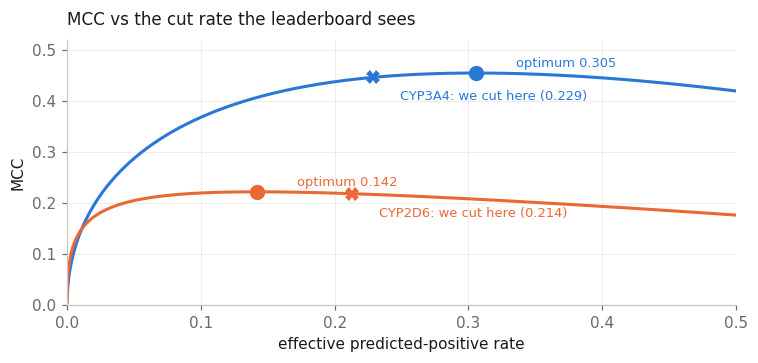

  CYP3A4: optimum effective 0.305 -> MCC 0.4557  (we scored 0.4470; gain +0.0087)  cut the FILE at 0.281
  CYP2D6: optimum effective 0.142 -> MCC 0.2226  (we scored 0.2180; gain +0.0046)  cut the FILE at 0.114
→ X = where we cut, dot = the optimum. The curve is flat near its peak, so a slightly wrong d′ costs little — cutting at the wrong END costs a lot.


In [13]:
def d_prime(a): return np.sqrt(2)*norm.ppf(np.clip(a, 1e-6, 1-1e-6))
def mcc_bn(d, prev, t):
    tpr, fpr = 1-norm.cdf(t-d), 1-norm.cdf(t)
    TP, FN, FP, TN = prev*tpr, prev*(1-tpr), (1-prev)*fpr, (1-prev)*(1-fpr)
    den = np.sqrt((TP+FP)*(TP+FN)*(TN+FP)*(TN+FN))
    return ((TP*TN-FP*FN)/den if den > 0 else 0.), TP+FP

fig, ax = panel('MCC vs the cut rate the leaderboard sees',
                xlabel='effective predicted-positive rate', ylabel='MCC')
ts = np.linspace(-3, 5, 4000)
for c in ISOS:
    v = [mcc_bn(OUR_DPRIME[c], PREVALENCE[c], t) for t in ts]
    r, m = np.array([x[1] for x in v]), np.array([x[0] for x in v])
    o = np.argsort(r); ax.plot(r[o], m[o], lw=2, color=CLR[c])
    b = int(np.argmax(m))
    ax.plot(r[b], m[b], 'o', ms=9, color=CLR[c])
    ax.annotate(f'optimum {r[b]:.3f}', (r[b], m[b]), (r[b]+.03, m[b]+.012),
                fontsize=8.5, color=CLR[c])
    j = int(np.argmin(abs(r-LAST_EFFECTIVE[c])))
    ax.plot(r[j], m[j], 'X', ms=9, color=CLR[c], mew=0)
    ax.annotate(f'{c}: we cut here ({LAST_EFFECTIVE[c]:.3f})', (r[j], m[j]),
                (r[j]+.02, m[j]-.045), fontsize=8.5, color=CLR[c])
ax.set_xlim(0, .5); ax.set_ylim(0, .52)
plt.show()
for c in ISOS:
    v = [mcc_bn(OUR_DPRIME[c], PREVALENCE[c], t) for t in ts]
    m = np.array([x[0] for x in v]); r = np.array([x[1] for x in v]); b = int(np.argmax(m))
    print(f'  {c}: optimum effective {r[b]:.3f} -> MCC {m[b]:.4f}  '
          f'(we scored {BEST_MCC[c]:.4f}; gain {m[b]-BEST_MCC[c]:+.4f})  '
          f'cut the FILE at {r[b]/RATE_INFLATION[c]:.3f}')
takeaway('X = where we cut, dot = the optimum. The curve is flat near its peak, so a '
         'slightly wrong d′ costs little — cutting at the wrong END costs a lot.')

### 11b · Does out-of-fold predict the leaderboard?

Convert AUC to d′ on both sides and compare. This is the honesty check for every number
above.

NameError: name 'auc' is not defined

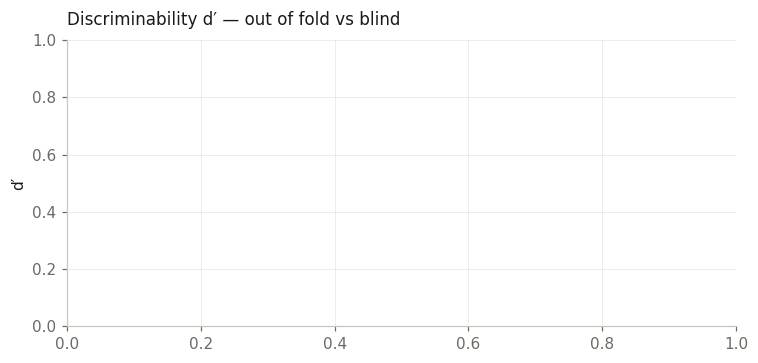

In [14]:
fig, ax = panel("Discriminability d′ — out of fold vs blind", ylabel="d′")
x = np.arange(len(ISOS)); w = .34
o = [d_prime(auc[c]['BLEND']) for c in ISOS]; b = [OUR_DPRIME[c] for c in ISOS]
ax.bar(x-w/2, o, w*.92, color=[CLR[c] for c in ISOS], alpha=.45, label='out of fold')
ax.bar(x+w/2, b, w*.92, color=[CLR[c] for c in ISOS], label='blind (from leaderboard)')
for xi, v in zip(x-w/2, o): ax.text(xi, v+.02, f'{v:.2f}', ha='center', fontsize=9)
for xi, v in zip(x+w/2, b): ax.text(xi, v+.02, f'{v:.2f}', ha='center', fontsize=9)
ax.set_xticks(x, ISOS); ax.legend(loc='upper left')
plt.show()
for c in ISOS:
    print(f'  {c}: ratio blind/OOF = {OUR_DPRIME[c]/d_prime(auc[c]["BLEND"]):.2f}')
takeaway('CYP3A4 transfers almost exactly. CYP2D6 out-of-fold badly UNDERSTATES the '
         'model — the 22%-vs-7% prevalence gap from §4b, so judge CYP2D6 ideas gently.')

## 12 · Refit on everything and predict the blind set

Cross-validation was for measuring; the submission refits on all labelled rows.

In [ ]:
# The optimal cut rate is a function of d', so a better score column moves it. Reusing
# OPTIMAL_RATE (solved at the OLD d' of 1.290 / 0.980) throws away part of the gain.
def _mcc_b(d, prev, t):
    tpr, fpr = 1-norm.cdf(t-d), 1-norm.cdf(t)
    TP, FN = prev*tpr, prev*(1-tpr); FP, TN = (1-prev)*fpr, (1-prev)*(1-fpr)
    den = np.sqrt((TP+FP)*(TP+FN)*(TN+FP)*(TN+FN))
    return (TP*TN-FP*FN)/den if den > 0 else 0.0, TP+FP

SHRINK = {c: OUR_DPRIME[c]/d_prime(auc_sel[c]) for c in ISOS} if False else \
         {'CYP3A4': 1.00, 'CYP2D6': 2.25}      # measured OOF->blind d' transfer
OPT = {}
for c in ISOS:
    d = d_prime(roc_auc_score(oof[c]['_y'], blend_of(c, picked[c]))) * SHRINK[c]
    ts = np.linspace(-3, 5, 4000); v = [_mcc_b(d, PREVALENCE[c], t) for t in ts]
    i = int(np.argmax([x[0] for x in v])); OPT[c] = v[i][1]
    print(f'{c}: corrected d\' {d:.3f} -> optimal EFFECTIVE rate {OPT[c]:.3f} '
          f'(was {OPTIMAL_RATE[c]:.3f}),  predicted MCC {v[i][0]:.4f}')
CUT_RATE = {c: OPT[c]/RATE_INFLATION[c] for c in ISOS}   # SUBMITTED rate
blind = {}
for c in ISOS:
    sub = lab[lab.isoform == c].reset_index(drop=True)
    r = np.array([row_of[i] for i in sub[CC.ID_COL]]); y = sub.y.to_numpy().astype(int)
    use = picked[c]                       # <-- §9e's members, not all of them
    per = []
    for i, n in enumerate(use, 1):
        b = ZOO[n]['blocks']
        per.append(rank01(ZOO[n]['fn'](view(Xtr, b)[r], y, view(Xte, b))))
        print(f'  {c} [{i}/{len(use)}] {n}', flush=True)
    blind[c] = np.mean(per, axis=0)

fig, axes = panels('Blind-set scores and where the cut falls', n=2)
for ax, c in zip(axes, ISOS):
    cut = float(np.quantile(blind[c], 1-CUT_RATE[c]))
    # SHARED bin edges -- letting the subset re-bin over its own range makes the
    # coloured bars narrower than the grey ones and silently misaligned
    edges = np.linspace(blind[c].min(), blind[c].max(), 46)
    ax.hist(blind[c], bins=edges, color=GREY, lw=0)
    ax.hist(blind[c][blind[c] >= cut], bins=edges, color=CLR[c], lw=0)
    ax.axvline(cut, color=INK, lw=1.5, ls='--')
    ax.set_title(f'{c}  —  {(blind[c]>=cut).mean():.1%} called positive',
                 loc='left', fontsize=10, color=CLR[c])
    ax.set_xlabel('blend score')
axes[0].set_ylabel('compounds')
plt.show()
takeaway('Coloured = predicted TDI. Rates should read ~0.28 (CYP3A4) and ~0.11 (CYP2D6) '
         'of the file, which land on the effective targets after inflation.')

### 12b · Diff against the standing best — the gate

Column agreement is the wrong statistic. `tdi_recut` changed 2.1% of labels and lost
0.036, because a label only flips when its score sits near the cut, and those are the
rows MCC is most sensitive to.

In [ ]:
sub_df = test[[CC.SMILES_COL, CC.ID_COL]].copy()
for c in ISOS:
    sub_df[f'{c}_is_TDI'] = blind[c] >= float(np.quantile(blind[c], 1-CUT_RATE[c]))

base = ART / 'submission_tdi_best.csv'
if base.exists():
    old = pd.read_csv(base); old.columns = [x.strip() for x in old.columns]
    j = sub_df.merge(old, on=CC.ID_COL, suffixes=('_new', '_old'))
    fig, axes = panels('Where the flipped labels sit relative to the cut', n=2)
    for ax, c in zip(axes, ISOS):
        a = j[f'{c}_is_TDI_new'].astype(bool).to_numpy()
        b = j[f'{c}_is_TDI_old'].astype(bool).to_numpy()
        s = pd.Series(blind[c], index=test[CC.ID_COL]).loc[j[CC.ID_COL]].to_numpy()
        pct = pd.Series(s).rank(pct=True).to_numpy(); ch = a != b
        edges = np.linspace(0, 1, 41)          # shared edges, as above
        ax.hist(pct[~ch], bins=edges, color=GREY, lw=0, label='unchanged')
        ax.hist(pct[ch],  bins=edges, color=ORANGE, lw=0, label='flipped')
        ax.axvline(1-CUT_RATE[c], color=INK, lw=1.5, ls='--')
        ax.set_title(f'{c} — {ch.sum()} flips, {100*(1-ch.mean()):.1f}% agreement',
                     loc='left', fontsize=10, color=CLR[c])
        ax.set_xlabel('score percentile')
    axes[0].set_ylabel('compounds'); axes[0].legend(loc='upper left', fontsize=8)
    plt.show()
    takeaway('Flips clustered ON the dashed line are the dangerous kind. Flips spread far '
             'from it mean the SCORES changed, not just the cut — and then §11 cannot '
             'predict the outcome.')
else:
    print('submission_tdi_best.csv not found — run the diff before submitting.')

WRITE, OUT_TAG = False, 'nb_v1'
if WRITE:
    p = ART / f'submission_{OUT_TAG}.csv'; sub_df.to_csv(p, index=False)
    for c in ISOS:
        pd.DataFrame({CC.ID_COL: test[CC.ID_COL], f'{c}_score': blind[c]}).to_csv(
            ART / f'nb_scores_{c}_{OUT_TAG}.csv', index=False)
    print(f'written {p} (+ per-endpoint scores, so a re-threshold needs no refit)')
else:
    print('\nWRITE is False — nothing written. Read the chart above, then set WRITE = True.')

## 13 · What to try next

Every claim traces to a cell — fill the right column from your own run.

| question | cell | what you saw |
|---|---|---|
| Is the label rule exact? | §3 | |
| Is our CV harder or easier than the blind task? | §5b | |
| Best model per endpoint? | §9 | |
| Any redundant members? | §9c | |
| Anything hurting the blend? | §9d | |
| Does Route B help? | §10 | |
| Does out-of-fold predict the blind set? | §11b | |

### Ranked candidates

**1 · The unused CYP1A2 / CYP2C9 labels** (the grey bars in §2b — 2,698 rows). TDI is
mechanism-based, largely independent of which isoform bioactivates the compound. Train one
model over all four with a one-hot isoform indicator; CYP2D6 at 1,497 rows has most to gain.

**2 · Route B, properly.** §10 gives it one shot with one feature set and `SCALE` fixed at
0.20. Try per-arm feature subsets, censored regression for the unfitted direct arms
(`measurable` already marks them), and fitting `SCALE` out of fold.

**3 · Class weighting for CYP2D6.** §4b shows 22% training against 7% blind. Add
`scale_pos_weight` to the zoo entries and re-read §9.

**4 · Richer mechanism chemistry.** If `lgb_alert` scores respectably in §9 on 1% of the
columns, the alerts are real signal and deserve counts or alert×context rather than presence.

**5 · A different representation.** §9c shows how little disagreement there is between
members. `unimol_kaggle_cyp_tdi_5fold.ipynb` is the cheapest genuinely different one.

### One thing not to try

**CYP2D6 pIC50 as a TDI feature.** Measured: AUC 0.4409 — *inverted* — degrading the blend
to −0.058 at weight 0.40. TDI is a shift after preincubation, and a compound that is
already a potent direct inhibitor has no headroom left to shift.